In [5]:
import os,math,warnings,random
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 

import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, coint
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
np.set_printoptions(suppress=True,precision=6)
pd.set_option("display.width",160)
pd.set_option("display.max_columns",50)

random.seed(2021); np.random.seed(2021)

In [7]:
display(Markdown("## Download and align prices with a preset pair" \
"\n Both series are placed on the same 'clock' "))

import yfinance as yf 

A,B = "PEP", "KO"

rawA = yf.download(A,start="2017-01-01", auto_adjust=True, progress=False)
rawB = yf.download(B, start="2017-01-01", auto_adjust=True, progress=False)

sA = rawA["Close"].copy(); sA.name = A
sB = rawB['Close'].copy(); sB.name = B

px = pd.concat([sA,sB], axis=1).sort_index().ffill().dropna()
px.head(), px.tail(), px.describe()

## Download and align prices with a preset pair
 Both series are placed on the same 'clock' 

(Ticker            PEP         KO
 Date                            
 2017-01-03  80.474541  31.739393
 2017-01-04  80.628334  31.625490
 2017-01-05  80.520691  31.701420
 2017-01-06  80.405350  31.693832
 2017-01-09  79.559448  31.374916,
 Ticker             PEP         KO
 Date                             
 2025-10-27  152.630005  70.059998
 2025-10-28  150.119995  70.160004
 2025-10-29  146.160004  68.349998
 2025-10-30  147.550003  68.980003
 2025-10-31  146.289993  68.525002,
 Ticker          PEP           KO
 count   2221.000000  2221.000000
 mean     127.740771    48.924488
 std       29.100968    11.182438
 min       76.575233    30.706724
 25%       96.434120    38.460487
 50%      127.819633    47.924168
 75%      155.117172    57.177013
 max      180.582443    72.819817)

In [10]:
display(Markdown("## Checks" \
"\n If its near zero the pair is unlikely to co-move in a stable way"))

ret = px.pct_change().dropna()
print("Annualized vol (approx):")
print((ret.std() * np.sqrt(252)).to_frame("ann_vol").T)

print("\nCorrelation:")
print(ret[A].corr(ret[B]))

## Checks
 If its near zero the pair is unlikely to co-move in a stable way

Annualized vol (approx):
Ticker        PEP        KO
ann_vol  0.199858  0.185201

Correlation:
0.7184337768007311


## OLS Hedge ratio from first principles and intercept

In pairs $\beta$ tells you how many units of B hedge A. Intercept $a$ captures a fixed price offset
- For cointegration, we care about residuals $e_t = y_t - (a+\beta x_t)$
- For trading, many use a no-intercept spread $s_t = y_t - \beta x_t$ tp stay dollar-neutral. Both are fine if you understand the difference

In [26]:
# 1) Sample Means
x = px[B]; y = px[A]
xbar, ybar = x.mean(), y.mean()
print(f"Sample Means B:{xbar} A:{ybar}")

# 2) Center for covariance/variance
x_c = x - xbar
y_c = y- ybar

# 3) OLS slope (with intercept) equal Cov(x,y)/Var(x)
beta = (x_c @ y_c) / (x_c @ x_c)

a = ybar - beta * xbar

print(f"beta (slope) = {beta:.6f}")
print(f"a (intercept) = {a:.6f}")

X = sm.add_constant(x.values)
ols = sm.OLS(y.values, X, missing='drop').fit()

print("\nOLS check (statsmodels):")
print({"const": float(ols.params[0]), "beta": float(ols.params[1])})

Sample Means B:48.924488469535625 A:127.74077050399265
beta (slope) = 2.239411
a (intercept) = 18.178730

OLS check (statsmodels):
{'const': 18.178730370449166, 'beta': 2.2394110508026217}


## Build residuals two ways and compare 

Removing the intercept changes the spread's level (mean) but nots its fluctuation around equilibrium.

In [ ]:
# Engle- Granger residuals (regression with intercept)
e = y - (a + beta * x) # mean should ~0 if regression fit was good
e.name = "EG_resid"

s = y - beta * x
s.name = "spread"

stats = pd.DataFrame({
    "EG_resid_mean" : [e.mean()],
    "EG_resid_std": [e.std()],
    "spread_mean" : [s.mean()],
    "spread_std": [s.std()]
})

stats

,EG_resid_mean,EG_resid_std,spread_mean,spread_std
0,2.047489e-15,14.824332,18.17873,14.824332


## Stationarity of the spread (ADF) and cointeration (Engle-Granger)

- Cointegration means a linear combo of prices is stationary- they wander but stay "tethered"
- ADF checks stationary directly on your spread. We generally want $p < 0.05$

In [31]:
# ADF on the residuals/spread: H0 = "has unit root"
# small p-value -> reject H0 -> stationary -> good for mean reversion

adf_e = adfuller(e.dropna(), autolag="AIC")
adf_s = adfuller(s.dropna(), autolag="AIC")

print("ADF on EG residuals: p-value =", adf_e[1])
print("ADF on no-intercept spread: p-value=",adf_s[1])

# Engle-Granger cointegration test on levels (prices)
# H0: not cointegrated. Small p-value -> cointegrated 
eg_stat, eg_pval, _ = coint(y.dropna(), x.dropna())
print("\nEngle-Granger on prices: p-value =", eg_pval)


ADF on EG residuals: p-value = 0.6126500475630192
ADF on no-intercept spread: p-value= 0.6126500475628158

Engle-Granger on prices: p-value = 0.8183955423103852


## Mean-reversion speed via AR(1) half-life (OU intuition)
If $phi < 0$,shocks decay back to equilibrium. Half-life is "how many days until a shock halves." 


Shorter half-life -> faster mean reversion -> more trading opportunities

In [33]:
# We model the spread as an AR(1) in *differences*: Δs_t = φ * s_{t-1} + ε_t
# (Discrete-time OU model linearized around its mean.)
# Half-life ≈ -ln(2) / φ, when φ < 0 (mean-reverting).

s_ = s.dropna()
ds = s_.diff().dropna()
lag = s_.shift(1).reindex(ds.index)

# Regress Δs_t on [const, s_{t-1}]
X = sm.add_constant(lag.values)
phi = sm.OLS(ds.values, X).fit().params[-1]  # slope on s_{t-1}

hl = float(-np.log(2)/phi) if phi < 0 else np.inf
print({"phi": float(phi), "half_life_days": hl})


{'phi': -0.002251120177673563, 'half_life_days': 307.9121174580219}


## Rolling z-score (signal scaffold)

Z-scores make the spread scale-free. A common rule of thumb is enter at $\left| z \right| \ge 2$, exit near $\left| z \right| \le 0.5-1$

This will be converted to positions later

First non-NaN z:
 Date
2017-03-29    1.260474
2017-03-30    0.993280
2017-03-31    0.972848
Name: z(60), dtype: float64

Last 3 z:
 Date
2025-10-29   -0.103407
2025-10-30   -0.158536
2025-10-31   -0.283962
Name: z(60), dtype: float64


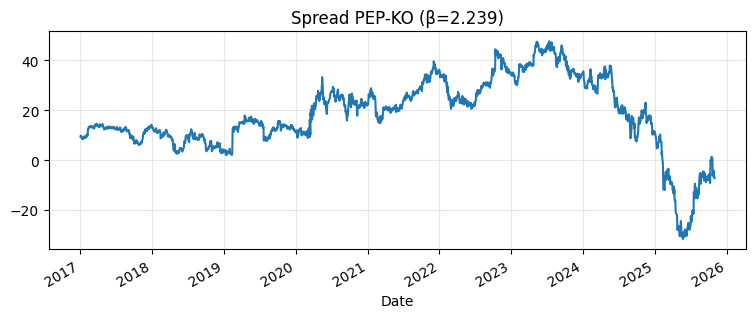

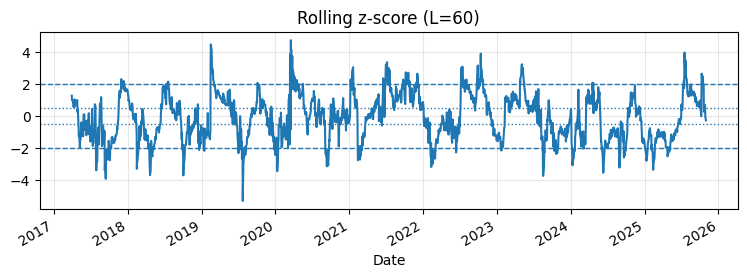

In [34]:
LOOKBACK = 60

m = s.rolling(LOOKBACK, min_periods=LOOKBACK).mean()
v = s.rolling(LOOKBACK, min_periods=LOOKBACK).std()

z = (s - m) / v
z.name = f"z({LOOKBACK})"

print("First non-NaN z:\n", z.dropna().head(3))
print("\nLast 3 z:\n", z.dropna().tail(3))

# quick plots
fig, ax = plt.subplots(figsize=(9,3.2))
s.plot(ax=ax)
ax.set_title(f"Spread {A}-{B} (β={beta:.3f})")
ax.grid(True, alpha=0.3)
plt.show()

fig, ax = plt.subplots(figsize=(9,2.6))
z.plot(ax=ax)
for h in [2.0, -2.0, 0.5, -0.5]:
    ax.axhline(h, ls="--" if abs(h)==2.0 else ":", lw=1)
ax.set_title(f"Rolling z-score (L={LOOKBACK})")
ax.grid(True, alpha=0.3)
plt.show()
